In [2]:
%pip install matplotlib

  Obtaining dependency information for matplotlib from https://files.pythonhosted.org/packages/04/93/0d239bde12b308262265c2d98909b2f0ecad2b5deeae96241642e822e9c7/matplotlib-3.11.2-cp312-cp312-win_amd64.whl.metadata
     ---------------------------------------- 0.0/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     ----- ---------------------------------- 10.2/80.3 kB ? eta -:--:--
     -------------- ----------------------- 30.7/80.3 kB 259.2 kB/s eta 0:00:01
     ------------------- ------------------ 41.0/80.3 kB 217.9 kB/s eta 0:00:01
     --------------------------------- ---- 71.7/80.3 kB 326.8 kB/s eta 0:00:01
     -------------------------------------- 80.3/80.3 kB 319.7 kB/s eta 0:00:00
  Obtaining dependency information for contourpy>=1.0.1 from https://files.pythonhosted.org/packages/50/a9/dab08786bb4d77ef9a046b3c1be923be4e73c5d07d91f5a54e8ea9b09e41/contourpy-1.4.0-cp312-cp312-win_amd64.whl.metadata
  Obtaining dependency infor


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


# 1. Import thư viện
#
Sử dụng các thư viện:
#
- `pandas`, `numpy`: đọc và xử lý dữ liệu.
- `matplotlib`: vẽ biểu đồ.
- `StandardScaler`: chuẩn hóa dữ liệu trước khi K-Means.
- `KMeans`: thực hiện phân cụm.
- `silhouette_score`: đánh giá chất lượng phân cụm.
- `PCA`: dùng để trực quan hóa dữ liệu PCA trong trường hợp cần đưa dữ liệu về 2 chiều.


In [12]:
import os
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

# 2. Đọc dataset
#
Đầu vào gồm hai file:
#
- `cleaned_data.csv`: dữ liệu gốc đã được làm sạch ở Stage 1.
- `pca_data.csv`: dữ liệu đã được giảm chiều bằng PCA 
#
Hai file cần giữ thông tin `original_index` để có thể map kết quả Cluster_Label trở lại đúng dòng của dataset gốc.


In [13]:
ORIGINAL_FILE = "cleaned_data.csv"
PCA_FILE = "pca_data.csv"

if not os.path.exists(ORIGINAL_FILE):
    raise FileNotFoundError(
        f"Không tìm thấy {ORIGINAL_FILE}. "
        "Hãy đặt file notebook cùng thư mục với cleaned_data.csv."
    )

if not os.path.exists(PCA_FILE):
    raise FileNotFoundError(
        f"Không tìm thấy {PCA_FILE}. "
        "Hãy đặt file notebook cùng thư mục với pca_data.csv."
    )

df = pd.read_csv(ORIGINAL_FILE)
df_pca = pd.read_csv(PCA_FILE)

print("Kích thước cleaned_data.csv:", df.shape)
print("Kích thước pca_data.csv:", df_pca.shape)

print("\nCác cột cleaned_data.csv:")
print(df.columns.tolist())

print("\nCác cột pca_data.csv:")
print(df_pca.columns.tolist())

display(df.head())



Kích thước cleaned_data.csv: (689, 21)
Kích thước pca_data.csv: (689, 7)

Các cột cleaned_data.csv:
['product_name', 'price', 'tv_type', 'screen_size', 'resolution', 'screen_type', 'operating_system', 'ram', 'rom', 'release_year', 'manufacturer', 'model_name', 'rating', 'num_reviews', 'specifications', 'source', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity', 'data_date']

Các cột pca_data.csv:
['original_index', 'PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,model_name,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,7370,453,3.2,145,2026-01-01
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,960,373,4.3,66,2026-01-02
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5490,492,4.5,41,2026-01-03
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5291,292,4.7,117,2026-01-04
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026.0,...,Unknown,4.3,7.0,Unknown,dienmayxanh,5834,38,3.2,124,2026-01-05


# 3. Kiểm tra dữ liệu
#
Trước khi chạy K-Means, cần kiểm tra:
#
- Số dòng của hai dataset.
- Các cột dữ liệu.
- Missing values.
- Các cột numeric có thể sử dụng cho clustering.
#
K-Means tính khoảng cách giữa các điểm dữ liệu nên các feature đưa vào mô hình phải ở dạng số.


In [14]:
print("===== THÔNG TIN DATASET GỐC =====")
print("Số dòng:", len(df))
print("Số cột:", len(df.columns))

print("\nMissing values:")
display(df.isnull().sum())

print("\n===== THÔNG TIN PCA DATA =====")
print("Số dòng:", len(df_pca))
print("Số cột:", len(df_pca.columns))

print("\nMissing values:")
display(df_pca.isnull().sum())

===== THÔNG TIN DATASET GỐC =====
Số dòng: 689
Số cột: 21

Missing values:


product_name        0
price               0
tv_type             0
screen_size         0
resolution          0
screen_type         0
operating_system    0
ram                 0
rom                 0
release_year        0
manufacturer        0
model_name          0
rating              0
num_reviews         0
specifications      0
source              0
monthly_views       0
monthly_orders      0
customer_rating     0
stock_quantity      0
data_date           0
dtype: int64


===== THÔNG TIN PCA DATA =====
Số dòng: 689
Số cột: 7

Missing values:


original_index    0
PC1               0
PC2               0
PC3               0
PC4               0
PC5               0
PC6               0
dtype: int64

# 4. Chọn Features cho dữ liệu Original
#
Dữ liệu Original được lấy từ các cột numeric trong `cleaned_data.csv`.
#
Không sử dụng:
#
- `Cluster_Label` nếu cột này đã tồn tại.
- Các cột định danh như `original_index`, `ID`, `index`, `Unnamed: 0`.
#
Các cột text không được đưa trực tiếp vào K-Means vì K-Means cần dữ liệu dạng số.



In [15]:
def get_original_features(data):
    numeric_data = data.select_dtypes(include=np.number).copy()

    # Không sử dụng các cột định danh hoặc label cũ
    remove_cols = []

    for col in numeric_data.columns:
        col_lower = str(col).lower()

        if col_lower in [
            "id",
            "index",
            "original_index",
            "unnamed: 0",
            "cluster_label",
            "cluster"
        ]:
            remove_cols.append(col)

    numeric_data = numeric_data.drop(
        columns=remove_cols,
        errors="ignore"
    )

    # Thay infinity bằng NaN
    numeric_data = numeric_data.replace(
        [np.inf, -np.inf],
        np.nan
    )

    # Điền missing bằng median
    numeric_data = numeric_data.fillna(
        numeric_data.median(numeric_only=True)
    )

    # Loại cột vẫn còn toàn NaN
    numeric_data = numeric_data.dropna(
        axis=1,
        how="all"
    )

    return numeric_data


X_original_df = get_original_features(df)

print("Các feature Original được sử dụng:")
print(X_original_df.columns.tolist())

print("\nSố feature Original:", X_original_df.shape[1])
print("Số dòng Original:", X_original_df.shape[0])


Các feature Original được sử dụng:
['price', 'release_year', 'rating', 'num_reviews', 'monthly_views', 'monthly_orders', 'customer_rating', 'stock_quantity']

Số feature Original: 8
Số dòng Original: 689


# 5. Chuẩn hóa dữ liệu Original
#
K-Means dựa trên khoảng cách giữa các điểm dữ liệu.
#
Nếu một feature có giá trị rất lớn so với feature khác thì feature lớn có thể chi phối khoảng cách.
#
Vì vậy sử dụng `StandardScaler()` để đưa các feature về cùng thang đo.
#
Công thức:
#
**z = (x - mean) / standard deviation**



In [16]:
scaler_original = StandardScaler()

X_original_scaled = scaler_original.fit_transform(
    X_original_df
)

print("Đã hoàn thành StandardScaler cho Original Data.")
print("Kích thước dữ liệu sau scaling:", X_original_scaled.shape)

Đã hoàn thành StandardScaler cho Original Data.
Kích thước dữ liệu sau scaling: (689, 8)


# 6. Chuẩn bị dữ liệu PCA
#
`pca_data.csv` là dữ liệu đã được giảm chiều ở Stage trước.
#
Trong file PCA, `original_index` chỉ dùng để xác định dòng tương ứng với dataset gốc nên **không được đưa vào K-Means**.
#
Các cột `PC1`, `PC2`, ..., `PCn` là các thành phần chính được dùng làm feature.


In [20]:
# Lấy các cột numeric
X_pca_df = df_pca.select_dtypes(
    include=np.number
).copy()

# original_index chỉ dùng để map dữ liệu,
# không phải feature để clustering.
remove_pca_cols = []

for col in X_pca_df.columns:
    col_lower = str(col).lower()

    if col_lower in [
        "original_index",
        "id",
        "index",
        "unnamed: 0",
        "cluster_label",
        "cluster"
    ]:
        remove_pca_cols.append(col)

X_pca_df = X_pca_df.drop(
    columns=remove_pca_cols,
    errors="ignore"
)

X_pca_df = X_pca_df.replace(
    [np.inf, -np.inf],
    np.nan
)

X_pca_df = X_pca_df.fillna(
    X_pca_df.median(numeric_only=True)
)

X_pca_df = X_pca_df.dropna(
    axis=1,
    how="all"
)

print("Các component PCA được sử dụng:")
print(X_pca_df.columns.tolist())

print("\nSố component PCA:", X_pca_df.shape[1])
print("Số dòng PCA:", X_pca_df.shape[0])


Các component PCA được sử dụng:
['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6']

Số component PCA: 6
Số dòng PCA: 689


# 7. Chuẩn hóa dữ liệu PCA
#
Mặc dù dữ liệu đã được xử lý bằng PCA, trước khi chạy K-Means vẫn chuẩn hóa lại các component để việc tính khoảng cách giữa các điểm dữ liệu không bị một component chi phối quá mức.


In [21]:
scaler_pca = StandardScaler()

X_pca_scaled = scaler_pca.fit_transform(X_pca_df)

print("Đã hoàn thành StandardScaler cho PCA Data.")
print("Kích thước dữ liệu sau scaling:", X_pca_scaled.shape)

Đã hoàn thành StandardScaler cho PCA Data.
Kích thước dữ liệu sau scaling: (689, 6)


# 8. Thiết lập các giá trị K cần kiểm tra
#
Không chọn K theo cảm tính.
#
Ta thử nhiều giá trị K, từ 2 đến 10.
#
Với mỗi K sẽ tính:
#
- WCSS để xây dựng Elbow Plot.
- Silhouette Score để đánh giá chất lượng phân cụm.


In [22]:
K_MIN = 2
K_MAX = 10

k_values = list(
    range(K_MIN, K_MAX + 1)
)

RANDOM_STATE = 42

print("Các giá trị K được kiểm tra:")
print(k_values)

Các giá trị K được kiểm tra:
[2, 3, 4, 5, 6, 7, 8, 9, 10]


# 9. Elbow Method – WCSS
#
**WCSS (Within-Cluster Sum of Squares)** đo tổng khoảng cách bình phương giữa các điểm dữ liệu và centroid của cụm mà chúng thuộc về.
#
Khi tăng K, WCSS luôn có xu hướng giảm.
#
Ta tìm vị trí "khuỷu tay" trên biểu đồ để xác định K hợp lý.
#
Tuy nhiên, WCSS **không được dùng một mình** để chọn K. Sau đó cần kiểm tra thêm Silhouette Score.


In [23]:
def calculate_wcss(X, k_values):
    wcss = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )

        model.fit(X)

        wcss.append(model.inertia_)

    return wcss


wcss_original = calculate_wcss(
    X_original_scaled,
    k_values
)

wcss_pca = calculate_wcss(
    X_pca_scaled,
    k_values
)

wcss_table = pd.DataFrame({
    "K": k_values,
    "WCSS_Original": wcss_original,
    "WCSS_PCA": wcss_pca
})

display(wcss_table)


,K,WCSS_Original,WCSS_PCA
0,2,4876.879670,3608.160025
1,3,4364.971532,3138.130337
2,4,3847.758424,2740.860774
3,5,3439.150069,2312.308238
4,6,2974.175234,1897.526712
5,7,2732.527113,1666.838819
6,8,2490.765362,1518.600044
7,9,2282.846666,1389.807299
8,10,2145.353236,1283.113422


# 10. Biểu đồ Elbow – Original Data
#
Biểu đồ này thể hiện WCSS theo từng giá trị K trên dữ liệu gốc.
#
Khi đường cong bắt đầu giảm chậm lại, vị trí đó là ứng viên cho K tối ưu.


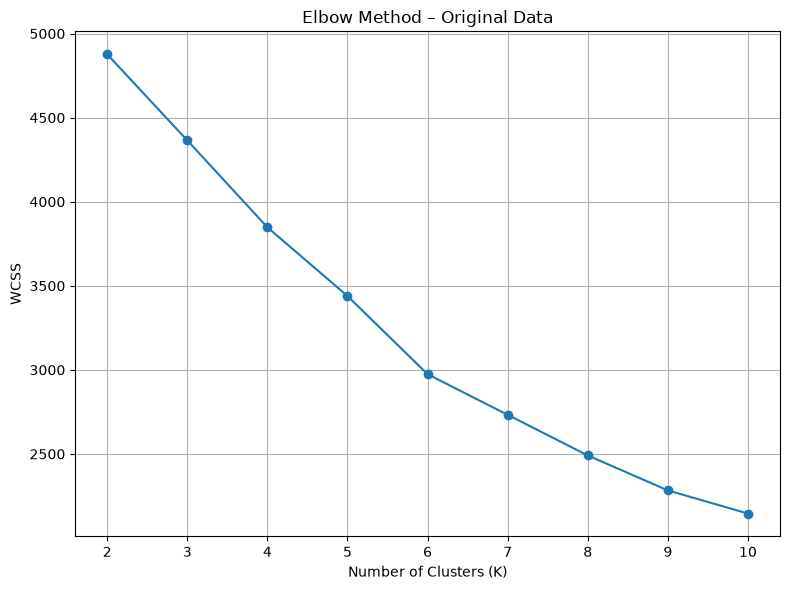

In [45]:
plt.figure(figsize=(8, 6))

plt.plot(
    k_values,
    wcss_original,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method – Original Data")
plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()

# 11. Biểu đồ Elbow – PCA Data
#
Tương tự dữ liệu Original, biểu đồ này sử dụng WCSS của dữ liệu sau PCA.


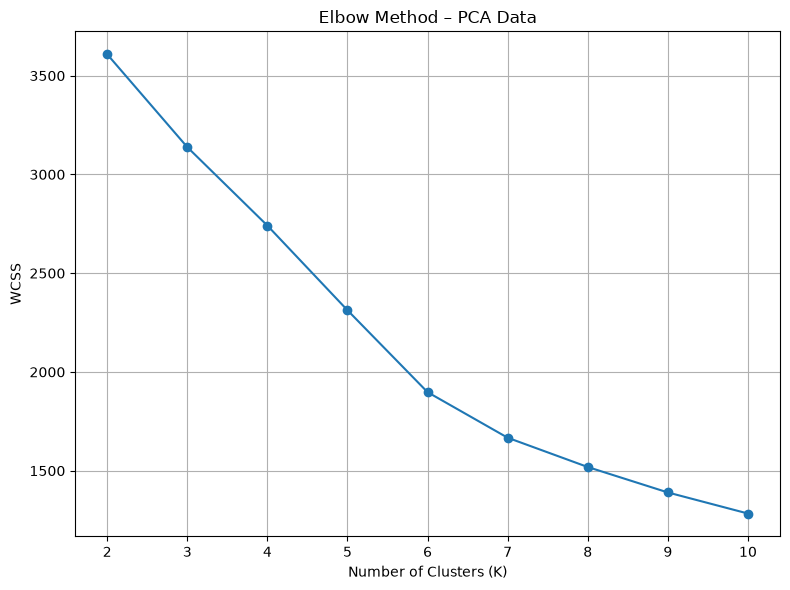

In [41]:
plt.figure(figsize=(8, 6))

plt.plot(
    k_values,
    wcss_pca,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS")
plt.title("Elbow Method – PCA Data")
plt.xticks(k_values)
plt.grid(True)

plt.tight_layout()
plt.show()

# 12. Silhouette Score
#
Silhouette Score đánh giá mức độ:
#
- Các điểm trong cùng một cluster gần nhau.
- Các cluster khác nhau tách biệt nhau.
#
Giá trị càng gần **1** thì chất lượng phân cụm càng tốt.
#
Cách diễn giải:
#
- Gần 1: phân cụm tốt.
- Gần 0: các cụm có thể chồng lấn.
- Nhỏ hơn 0: một số điểm có thể được phân vào cluster chưa phù hợp.
#
Ta tính Silhouette Score cho từng K từ 2 đến 10.


In [26]:
def calculate_silhouette(X, k_values):
    scores = []

    for k in k_values:
        model = KMeans(
            n_clusters=k,
            random_state=RANDOM_STATE,
            n_init=10
        )

        labels = model.fit_predict(X)

        score = silhouette_score(
            X,
            labels
        )

        scores.append(score)

    return scores


silhouette_original = calculate_silhouette(
    X_original_scaled,
    k_values
)

silhouette_pca = calculate_silhouette(
    X_pca_scaled,
    k_values
)

silhouette_table = pd.DataFrame({
    "K": k_values,
    "Silhouette_Original": silhouette_original,
    "Silhouette_PCA": silhouette_pca
})

display(silhouette_table)


,K,Silhouette_Original,Silhouette_PCA
0,2,0.865849,0.874232
1,3,0.125439,0.190795
2,4,0.152907,0.175563
3,5,0.134615,0.181762
4,6,0.142756,0.198651
5,7,0.148030,0.205185
6,8,0.163309,0.198578
7,9,0.164443,0.204358
8,10,0.164728,0.212461


# 13. Biểu đồ Silhouette Score
#
Biểu đồ giúp so sánh chất lượng phân cụm giữa các giá trị K.
#
K có Silhouette Score cao nhất là K được đề xuất theo tiêu chí Silhouette.


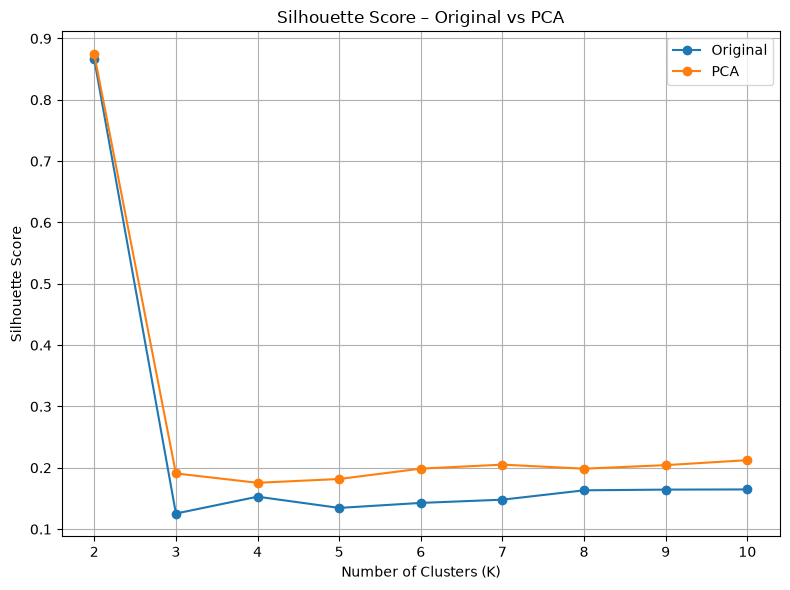

In [42]:
plt.figure(figsize=(8, 6))

plt.plot(
    k_values,
    silhouette_original,
    marker="o",
    label="Original"
)

plt.plot(
    k_values,
    silhouette_pca,
    marker="o",
    label="PCA"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score – Original vs PCA")
plt.xticks(k_values)
plt.grid(True)
plt.legend()

plt.tight_layout()

plt.show()

# 14. Chọn số cụm K
#
K được đề xuất dựa trên Silhouette Score cao nhất.
#
Tuy nhiên, khi viết báo cáo cần quan sát đồng thời:
#
- Elbow Plot: xem WCSS bắt đầu giảm chậm ở đâu.
- Silhouette Score: xem K nào tạo cluster tách biệt tốt.
#
Do đó K cuối cùng cần có sự phù hợp giữa hai phương pháp, không chỉ lấy một con số theo cảm tính.


In [28]:
best_k_original = k_values[
    int(np.argmax(silhouette_original))
]

best_k_pca = k_values[
    int(np.argmax(silhouette_pca))
]

best_sil_original = max(silhouette_original)
best_sil_pca = max(silhouette_pca)

print("===== K ĐƯỢC ĐỀ XUẤT =====")

print(
    f"Original Data: "
    f"K = {best_k_original}, "
    f"Silhouette = {best_sil_original:.4f}"
)

print(
    f"PCA Data: "
    f"K = {best_k_pca}, "
    f"Silhouette = {best_sil_pca:.4f}"
)

===== K ĐƯỢC ĐỀ XUẤT =====
Original Data: K = 2, Silhouette = 0.8658
PCA Data: K = 2, Silhouette = 0.8742


# 15. K-Means trên dữ liệu Original
#
Sau khi xác định K, tiến hành huấn luyện K-Means trên dữ liệu gốc đã được StandardScaler.
#
K-Means sẽ tạo ra `Cluster_Label` cho từng sản phẩm.

In [29]:
kmeans_original = KMeans(
    n_clusters=best_k_original,
    random_state=RANDOM_STATE,
    n_init=10
)

labels_original = kmeans_original.fit_predict(
    X_original_scaled
)

final_sil_original = silhouette_score(
    X_original_scaled,
    labels_original
)

print("K-Means Original hoàn thành.")
print("K =", best_k_original)
print("WCSS =", f"{kmeans_original.inertia_:,.4f}")
print(
    "Silhouette Score =",
    f"{final_sil_original:.4f}"
)

print("\nSố lượng sản phẩm trong từng cluster:")
print(
    pd.Series(labels_original)
    .value_counts()
    .sort_index()
)

K-Means Original hoàn thành.
K = 2
WCSS = 4,876.8797
Silhouette Score = 0.8658

Số lượng sản phẩm trong từng cluster:
0    688
1      1
Name: count, dtype: int64


# 16. K-Means trên dữ liệu PCA
#
Tiếp theo chạy K-Means trên dữ liệu sau PCA.
#
Ở đây PCA chỉ làm giảm số chiều dữ liệu; chính K-Means mới tạo ra các cluster.


In [30]:
kmeans_pca = KMeans(
    n_clusters=best_k_pca,
    random_state=RANDOM_STATE,
    n_init=10
)

labels_pca = kmeans_pca.fit_predict(
    X_pca_scaled
)

final_sil_pca = silhouette_score(
    X_pca_scaled,
    labels_pca
)

print("K-Means PCA hoàn thành.")
print("K =", best_k_pca)
print("WCSS =", f"{kmeans_pca.inertia_:,.4f}")
print(
    "Silhouette Score =",
    f"{final_sil_pca:.4f}"
)

print("\nSố lượng sản phẩm trong từng cluster:")
print(
    pd.Series(labels_pca)
    .value_counts()
    .sort_index()
)

K-Means PCA hoàn thành.
K = 2
WCSS = 3,608.1600
Silhouette Score = 0.8742

Số lượng sản phẩm trong từng cluster:
0    688
1      1
Name: count, dtype: int64


# 17. So sánh K-Means Original và PCA
#
Hai phương pháp được so sánh dựa trên:
#
- Số cluster K.
- WCSS.
- Silhouette Score.
- Số lượng feature sử dụng.
#
**Silhouette Score cao hơn** thường cho thấy chất lượng phân cụm tốt hơn.
#
Ngoài ra:
#
- Original giữ các feature ban đầu nên dễ giải thích ý nghĩa đặc trưng.
- PCA giảm số chiều và có thể loại bớt thông tin dư thừa, nhưng các PC khó giải thích trực tiếp như feature gốc.


In [31]:
comparison = pd.DataFrame({
    "Method": [
        "Original",
        "PCA"
    ],
    "K": [
        best_k_original,
        best_k_pca
    ],
    "WCSS": [
        kmeans_original.inertia_,
        kmeans_pca.inertia_
    ],
    "Silhouette_Score": [
        final_sil_original,
        final_sil_pca
    ],
    "Number_of_Features": [
        X_original_df.shape[1],
        X_pca_df.shape[1]
    ]
})

display(comparison)

comparison.to_csv(
    "clustering_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)


,Method,K,WCSS,Silhouette_Score,Number_of_Features
0,Original,2,4876.879670,0.865849,8
1,PCA,2,3608.160025,0.874232,6


# 18. Chọn phương pháp clustering cuối cùng
#
- Trong phần này chọn kết quả có Silhouette Score tốt hơn làm kết quả clustering chính.
#
- Nếu PCA có Silhouette cao hơn, sử dụng Cluster_Label từ PCA.
#
- Nếu Original có Silhouette cao hơn, sử dụng Cluster_Label từ Original.
#
- Việc lựa chọn này dựa trên metric chứ không chọn cảm tính.

In [32]:
if final_sil_pca > final_sil_original:
    final_method = "PCA"
    final_labels = labels_pca

elif final_sil_original > final_sil_pca:
    final_method = "Original"
    final_labels = labels_original

else:
    final_method = "PCA"
    final_labels = labels_pca

print("Phương pháp được chọn:", final_method)

print(
    "\nSilhouette Original:",
    f"{final_sil_original:.4f}"
)

print(
    "Silhouette PCA:",
    f"{final_sil_pca:.4f}"
)

Phương pháp được chọn: PCA

Silhouette Original: 0.8658
Silhouette PCA: 0.8742


# 19. Visualization – Cluster trên không gian PCA 2D
#
- Để trực quan hóa các cluster, đưa dữ liệu PCA về 2 chiều.
#
- Mỗi điểm đại diện cho một sản phẩm.
#
- Màu sắc biểu thị `Cluster_Label`.
#
- Tạo không gian 2D để trực quan hóa

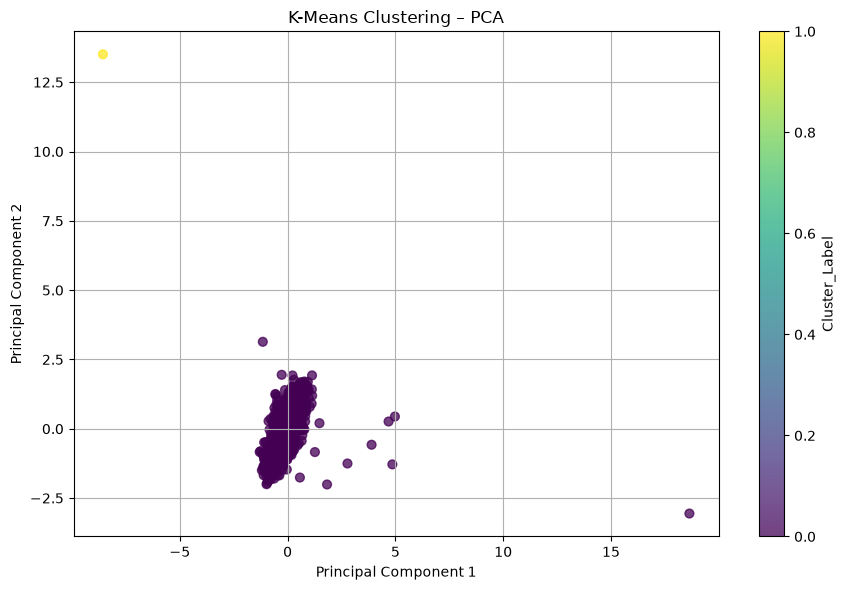

In [43]:
pca_visualizer = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

X_visual = pca_visualizer.fit_transform(
    X_pca_scaled
)

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_visual[:, 0],
    X_visual[:, 1],
    c=final_labels,
    cmap="viridis",
    s=40,
    alpha=0.75
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title(
    f"K-Means Clustering – {final_method}"
)

plt.colorbar(
    scatter,
    label="Cluster_Label"
)

plt.grid(True)
plt.tight_layout()


plt.show()

# 20. Kiểm tra Cluster_Label
#
- Sau khi chạy K-Means, mỗi sản phẩm phải có một `Cluster_Label`.
#
- Kiểm tra số lượng sản phẩm trong từng cluster trước khi map về dataset gốc.


In [34]:
cluster_counts = (
    pd.Series(final_labels)
    .value_counts()
    .sort_index()
)

print("Số lượng sản phẩm trong từng Cluster:")
display(
    cluster_counts.to_frame(
        name="Number_of_Products"
    )
)

Số lượng sản phẩm trong từng Cluster:


,Number_of_Products
0,688
1,1


# 21. Map Cluster_Label trở lại dataset gốc
#
Đây là bước quan trọng theo yêu cầu của Stage 2.
#
`Cluster_Label` không chỉ được lưu trong dữ liệu PCA mà phải được gắn trở lại `cleaned_data.csv`.
#
Nếu `pca_data.csv` có `original_index`, sử dụng cột này để map chính xác về dataset gốc.


In [35]:
df_clustered = df.copy()

if "original_index" in df_pca.columns:

    # Tạo bảng mapping giữa original_index và cluster
    cluster_mapping = pd.DataFrame({
        "original_index": df_pca["original_index"],
        "Cluster_Label": final_labels
    })

    # Map cluster về dataset gốc
    if "original_index" in df_clustered.columns:

        df_clustered = df_clustered.drop(
            columns=["Cluster_Label"],
            errors="ignore"
        )

        df_clustered = df_clustered.merge(
            cluster_mapping,
            on="original_index",
            how="left"
        )

    else:
        # Nếu cleaned_data không có original_index,
        # map theo vị trí sau khi kiểm tra số dòng.
        if len(df_clustered) != len(cluster_mapping):
            raise ValueError(
                "Không thể map Cluster_Label: "
                "số dòng giữa hai dataset không khớp."
            )

        df_clustered["Cluster_Label"] = (
            cluster_mapping["Cluster_Label"].values
        )

else:

    # Trường hợp PCA file không có original_index.
    # Chỉ map theo vị trí nếu hai file có cùng số dòng.
    if len(df_clustered) != len(final_labels):
        raise ValueError(
            "pca_data.csv không có original_index và "
            "số dòng không khớp với cleaned_data.csv."
        )

    df_clustered["Cluster_Label"] = final_labels


print("Đã gắn Cluster_Label vào dataset gốc.")

display(
    df_clustered[
        ["Cluster_Label"]
    ].head()
)


Đã gắn Cluster_Label vào dataset gốc.


,Cluster_Label
0,0
1,0
2,0
3,0
4,0


# 22. Kiểm tra kết quả sau khi map
#
Kiểm tra:
#
- Có giá trị `Cluster_Label` bị thiếu hay không.
- Tổng số sản phẩm sau khi map có giữ nguyên không.
- Số lượng sản phẩm của từng cluster.


In [36]:
print("Số dòng dataset gốc:", len(df))
print("Số dòng sau khi thêm Cluster_Label:", len(df_clustered))

print(
    "\nSố Cluster_Label bị thiếu:",
    df_clustered["Cluster_Label"].isna().sum()
)

print("\nPhân bố Cluster_Label:")
display(
    df_clustered["Cluster_Label"]
    .value_counts()
    .sort_index()
)

assert len(df_clustered) == len(df), (
    "Số dòng sau khi map không khớp dataset gốc!"
)

assert df_clustered["Cluster_Label"].isna().sum() == 0, (
    "Có Cluster_Label bị thiếu!"
)

Số dòng dataset gốc: 689
Số dòng sau khi thêm Cluster_Label: 689

Số Cluster_Label bị thiếu: 0

Phân bố Cluster_Label:


Cluster_Label
0    688
1      1
Name: count, dtype: int64

# 23. Xuất clustered_data.csv
#
Dataset cuối cùng chứa toàn bộ dữ liệu gốc và thêm cột:
#
`Cluster_Label`
#
File này sẽ được sử dụng cho các bước tiếp theo của project hoặc giao cho thành viên phụ trách UI.

In [37]:
OUTPUT_FILE = "clustered_data.csv"

df_clustered.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

print(f"Đã xuất file: {OUTPUT_FILE}")

display(df_clustered.head())

Đã xuất file: clustered_data.csv


,product_name,price,tv_type,screen_size,resolution,screen_type,operating_system,ram,rom,release_year,...,rating,num_reviews,specifications,source,monthly_views,monthly_orders,customer_rating,stock_quantity,data_date,Cluster_Label
0,Smart Tivi QNED LG AI 4K 65 inch 65QNED70BSA,18390000.0,Smart Tivi QNED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,webOS 26,Hãng không công bố,Hãng không công bố,2026.0,...,4.3,7.0,Unknown,dienmayxanh,7370,453,3.2,145,2026-01-01,0
1,Google Tivi Sony 4K 65 inch K-65S25VM2,19990000.0,Google Tivi,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2025.0,...,4.3,7.0,Unknown,dienmayxanh,960,373,4.3,66,2026-01-02,0
2,Google Tivi QLED TCL AI FHD 40 inch 40S5K,7690000.0,Google Tivi QLED,40 inch,Full HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,1 GB,8 GB,2025.0,...,4.3,7.0,Unknown,dienmayxanh,5490,492,4.5,41,2026-01-03,0
3,Google Tivi Sony 32 inch KD-32W830K,7690000.0,Google Tivi,32 inch,HD,Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,Hãng không công bố,16 GB,2022.0,...,4.3,7.0,Unknown,dienmayxanh,5291,292,4.7,117,2026-01-04,0
4,Google Tivi QLED TCL 4K 65 inch 65P7L,18490000.0,Google Tivi QLED,65 inch,4K (Ultra HD),Đèn nền: <a href='https://www.dienmayxanh.com/...,Google TV,2 GB,16 GB,2026.0,...,4.3,7.0,Unknown,dienmayxanh,5834,38,3.2,124,2026-01-05,0


# 24. Lưu bảng kết quả
# 
Lưu bảng so sánh Original và PCA để đưa vào báo cáo/slide.

In [38]:
results = pd.DataFrame({
    "Method": [
        "Original",
        "PCA"
    ],
    "K": [
        best_k_original,
        best_k_pca
    ],
    "WCSS": [
        kmeans_original.inertia_,
        kmeans_pca.inertia_
    ],
    "Silhouette_Score": [
        final_sil_original,
        final_sil_pca
    ],
    "Features": [
        X_original_df.shape[1],
        X_pca_df.shape[1]
    ]
})

results.to_csv(
    "clustering_results.csv",
    index=False,
    encoding="utf-8-sig"
)

display(results)

,Method,K,WCSS,Silhouette_Score,Features
0,Original,2,4876.879670,0.865849,8
1,PCA,2,3608.160025,0.874232,6


# 25. Kết luận K-Means
#
Kết luận cần dựa trên kết quả thực tế của notebook:

- Elbow Method được sử dụng để quan sát mức giảm WCSS khi K tăng.
- Silhouette Score được sử dụng để đánh giá mức độ tách biệt giữa các cluster.
- K-Means được chạy trên cả Original Data và PCA Data.
- Hai kết quả được so sánh bằng Silhouette Score.
- `Cluster_Label` của phương pháp được chọn được map trở lại dataset gốc.

In [39]:
print("========== KẾT LUẬN K-MEANS ==========")

print("\n--- Original Data ---")
print(f"K = {best_k_original}")
print(f"WCSS = {kmeans_original.inertia_:,.4f}")
print(f"Silhouette Score = {final_sil_original:.4f}")

print("\n--- PCA Data ---")
print(f"K = {best_k_pca}")
print(f"WCSS = {kmeans_pca.inertia_:,.4f}")
print(f"Silhouette Score = {final_sil_pca:.4f}")

print("\n--- KẾT QUẢ SO SÁNH ---")

if final_sil_pca > final_sil_original:
    print(
        "PCA có Silhouette Score cao hơn Original."
    )
    print(
        "=> PCA cho kết quả phân cụm tốt hơn theo Silhouette Score."
    )

elif final_sil_original > final_sil_pca:
    print(
        "Original có Silhouette Score cao hơn PCA."
    )
    print(
        "=> Original cho kết quả phân cụm tốt hơn theo Silhouette Score."
    )

else:
    print(
        "Hai phương pháp có Silhouette Score bằng nhau."
    )

print(
    f"\n=> Phương pháp được sử dụng cho Cluster_Label: {final_method}"
)

print(
    "\n=> File kết quả chính: clustered_data.csv"
)

========== KẾT LUẬN K-MEANS ==========

--- Original Data ---
K = 2
WCSS = 4,876.8797
Silhouette Score = 0.8658

--- PCA Data ---
K = 2
WCSS = 3,608.1600
Silhouette Score = 0.8742

--- KẾT QUẢ SO SÁNH ---
PCA có Silhouette Score cao hơn Original.
=> PCA cho kết quả phân cụm tốt hơn theo Silhouette Score.

=> Phương pháp được sử dụng cho Cluster_Label: PCA

=> File kết quả chính: clustered_data.csv
